# Predicting US Flight Delays

Dataset: USDOT 2015 Flight Delays (from Kaggle, loaded from HDFS)
Target: is_delayed = ARRIVAL_DELAY > 15 minutes (yes or no)

This notebook follows these steps:
1. Load the data
2. Look at the data & parse types (EDA & Parsing)
3. Clean the data
4. Feature Engineering (turn text into numbers)
5. Train 4 models (Spark ML logistic regression, TensorFlow MLP, XGBoost, Spark Random Forest)
6. Save the results for Streamlit

## **1) Start Spark and load the file from HDFS**
Spark is the tool we use to read and process the data. We initialize our `SparkSession` and read the file directly from HDFS.

In [1]:
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("flight-delays")
         .config("spark.driver.memory", "6g")  # 4g: Spark Random Forest runs out of heap
         .config("spark.hadoop.dfs.client.use.datanode.hostname", "true")
         # local mode on 8 cores: 200 default shuffle partitions = mostly task overhead
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .getOrCreate())
spark


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/20 13:11:07 WARN Utils: Your hostname, MacBook-Air-de-Jimi.local, resolves to a loopback address: 127.0.0.1; using 10.184.31.222 instead (on interface en0)
26/11/20 13:11:07 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/20 13:11:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/20 13:11:08 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


CSV reading options configured (header, delimiter)

In [2]:
raw = (spark.read
    .option("header", "true")
    .option("inferSchema", "false")  
    .option("delimiter", ",")
    .csv("hdfs://localhost:9000/data/raw/flights.csv")
)

n_raw = raw.count()
print("Rows:", n_raw)
print("Columns:", len(raw.columns))

Rows: 5819079
Columns: 31


**Result:** We have 5,819,079 rows and 31 columns. This matches the number Kaggle
announces for this dataset, so the file loaded correctly.

## **2) Parsing - Inspect and cast data types**

In [3]:
import pandas as pd
raw.printSchema() 
pd.set_option("display.max_columns", None)
raw.limit(5).toPandas()

/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/20 13:11:21 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


root
 |-- YEAR: string (nullable = true)
 |-- MONTH: string (nullable = true)
 |-- DAY: string (nullable = true)
 |-- DAY_OF_WEEK: string (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: string (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: string (nullable = true)
 |-- DEPARTURE_TIME: string (nullable = true)
 |-- DEPARTURE_DELAY: string (nullable = true)
 |-- TAXI_OUT: string (nullable = true)
 |-- WHEELS_OFF: string (nullable = true)
 |-- SCHEDULED_TIME: string (nullable = true)
 |-- ELAPSED_TIME: string (nullable = true)
 |-- AIR_TIME: string (nullable = true)
 |-- DISTANCE: string (nullable = true)
 |-- WHEELS_ON: string (nullable = true)
 |-- TAXI_IN: string (nullable = true)
 |-- SCHEDULED_ARRIVAL: string (nullable = true)
 |-- ARRIVAL_TIME: string (nullable = true)
 |-- ARRIVAL_DELAY: string (nullable = true)
 |-- D

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,0005,2354,-11,21,0015,205,194,169,1448,0404,4,0430,0408,-22,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,0010,0002,-8,12,0014,280,279,263,2330,0737,4,0750,0741,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,0020,0018,-2,16,0034,286,293,266,2296,0800,11,0806,0811,5,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,0020,0015,-5,15,0030,285,281,258,2342,0748,8,0805,0756,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,0025,0024,-1,11,0035,235,215,199,1448,0254,5,0320,0259,-21,0,0,NaN,NaN,NaN,NaN,NaN,NaN


**Column names validation:** Columns seem to use use short, clean names without spaces.

In [4]:
first_non_null = raw.select([F.first(c, ignorenulls=True).alias(c) for c in raw.columns]).first().asDict()
#pd.Series(first_non_null, name="example_value")
for col_name, example_val in first_non_null.items():
    print(f"{col_name} : {example_val}")

YEAR : 2015
MONTH : 1
DAY : 1
DAY_OF_WEEK : 4
AIRLINE : AS
FLIGHT_NUMBER : 98
TAIL_NUMBER : N407AS
ORIGIN_AIRPORT : ANC
DESTINATION_AIRPORT : SEA
SCHEDULED_DEPARTURE : 0005
DEPARTURE_TIME : 2354
DEPARTURE_DELAY : -11
TAXI_OUT : 21
WHEELS_OFF : 0015
SCHEDULED_TIME : 205
ELAPSED_TIME : 194
AIR_TIME : 169
DISTANCE : 1448
WHEELS_ON : 0404
TAXI_IN : 4
SCHEDULED_ARRIVAL : 0430
ARRIVAL_TIME : 0408
ARRIVAL_DELAY : -22
DIVERTED : 0
CANCELLED : 0
CANCELLATION_REASON : A
AIR_SYSTEM_DELAY : 25
SECURITY_DELAY : 0
AIRLINE_DELAY : 0
LATE_AIRCRAFT_DELAY : 0
WEATHER_DELAY : 0


### **2.1) Casting**
After inspection, every column (even numbers) is shown as **string**, this is because Spark loads everything as text by default to avoid a costly double read of the CSV file. 
 

We can confirm that we have:
* **5 text columns:** `AIRLINE`, `TAIL_NUMBER`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `CANCELLATION_REASON`.
* **26 numeric columns:** `YEAR`, `MONTH`, `DAY`, `DAY_OF_WEEK`, `FLIGHT_NUMBER`, `SCHEDULED_DEPARTURE`, `DEPARTURE_TIME`, `DEPARTURE_DELAY`, `TAXI_OUT`, `WHEELS_OFF`, `SCHEDULED_TIME`, `ELAPSED_TIME`, `AIR_TIME`, `DISTANCE`, `WHEELS_ON`, `TAXI_IN`, `SCHEDULED_ARRIVAL`, `ARRIVAL_TIME`, `ARRIVAL_DELAY`, `DIVERTED`, `CANCELLED`, `AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`, `LATE_AIRCRAFT_DELAY`, `WEATHER_DELAY`.

We cast all 26 numeric columns to `double` and verify the updated schema

In [5]:
numerical_cols = [
    "YEAR", "MONTH", "DAY", "DAY_OF_WEEK", "FLIGHT_NUMBER",
    "SCHEDULED_DEPARTURE", "DEPARTURE_TIME", "DEPARTURE_DELAY",
    "TAXI_OUT", "WHEELS_OFF", "SCHEDULED_TIME", "ELAPSED_TIME",
    "AIR_TIME", "DISTANCE", "WHEELS_ON", "TAXI_IN",
    "SCHEDULED_ARRIVAL", "ARRIVAL_TIME", "ARRIVAL_DELAY",
    "DIVERTED", "CANCELLED", "AIR_SYSTEM_DELAY", "SECURITY_DELAY",
    "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"
]

df_parsed = raw
for c in numerical_cols:
    df_parsed = df_parsed.withColumn(c, F.col(c).cast("double"))

df_parsed.printSchema()

root
 |-- YEAR: double (nullable = true)
 |-- MONTH: double (nullable = true)
 |-- DAY: double (nullable = true)
 |-- DAY_OF_WEEK: double (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: double (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: double (nullable = true)
 |-- DEPARTURE_TIME: double (nullable = true)
 |-- DEPARTURE_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- SCHEDULED_ARRIVAL: double (nullable = true)
 |-- ARRIVAL_TIME: double (nullable = true)
 |-- ARRIVAL_DELAY: double (nullable = true)
 |-- D

## **3) Smaller Sample for Exploration**

The full file has 5.8 million rows. We take a random 5% sample just for this exploring part. We will use the full file later, when we train the final model.

In [6]:
eda_sample = df_parsed.sample(fraction=0.05, seed=42).cache()
print("Sample size:", eda_sample.count())

Sample size: 290686


We have approximately 290k lines to use for data exploration

### **3.1) Check for Missing Values**
We count how many values are missing in each column.

In [7]:
missing_col_values = [F.sum(F.isnull(c).cast("int")).alias(c) for c in eda_sample.columns]
counts = eda_sample.select(missing_col_values).first().asDict()

sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)
for col_name, nb_missing in sorted_counts:
    print(f"{col_name} : {nb_missing}")

CANCELLATION_REASON : 286290
AIR_SYSTEM_DELAY : 237598
SECURITY_DELAY : 237598
AIRLINE_DELAY : 237598
LATE_AIRCRAFT_DELAY : 237598
WEATHER_DELAY : 237598
ELAPSED_TIME : 5148
AIR_TIME : 5148
ARRIVAL_DELAY : 5148
WHEELS_ON : 4542
TAXI_IN : 4542
ARRIVAL_TIME : 4542
TAXI_OUT : 4357
WHEELS_OFF : 4357
DEPARTURE_TIME : 4224
DEPARTURE_DELAY : 4224
TAIL_NUMBER : 734
YEAR : 0
MONTH : 0
DAY : 0
DAY_OF_WEEK : 0
AIRLINE : 0
FLIGHT_NUMBER : 0
ORIGIN_AIRPORT : 0
DESTINATION_AIRPORT : 0
SCHEDULED_DEPARTURE : 0
SCHEDULED_TIME : 0
DISTANCE : 0
SCHEDULED_ARRIVAL : 0
DIVERTED : 0
CANCELLED : 0


What we notice so far:
1. **Pre-departure features are 100% complete:** MONTH, DAY_OF_WEEK, AIRLINE, ORIGIN_AIRPORT, DESTINATION_AIRPORT, SCHEDULED_DEPARTURE, SCHEDULED_TIME, and DISTANCE all have 0 missing values.

2. **Huge missing counts in cancellation reason columns:** The 5 delay-cause columns (WEATHER_DELAY, AIRLINE_DELAY, LATE_AIRCRAFT_DELAY, AIR_SYSTEM_DELAY, SECURITY_DELAY) have 237,966 missing values because they are only filled in when a flight is actually delayed `(is_delayed == 1)`. Most flights aren't cancelled, so nulls here are normal.

3. **Medium missing counts:** in the columns ARRIVAL_DELAY, ELAPSED_TIME, AIR_TIME, WHEELS_ON, TAXI_IN, ARRIVAL_TIME, TAXI_OUT, WHEELS_OFF, DEPARTURE_TIME, DEPARTURE_DELAY, due to cancelled or diverted flights/

4. **Small missing count**: for the TAIL_NUMBER column which we won't use.


### **3.2) Distinct values per categorical column (full dataset)**
Next, we check how many unique values each text column has in our full `df_parsed` DataFrame.

In [8]:
cat_cols = ["AIRLINE", "TAIL_NUMBER", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "CANCELLATION_REASON"]

# one Spark job for all columns instead of one per column
distinct_counts = df_parsed.select([F.countDistinct(F.col(c)).alias(c) for c in cat_cols]).first().asDict()

#pd.Series(distinct_counts, name="distinct_values").sort_values(ascending=False)
sorted_distinct = sorted(distinct_counts.items(), key=lambda x: x[1], reverse=True)
for col_name, nb_distinct in sorted_distinct:
    print(f"{col_name}: {nb_distinct}")

TAIL_NUMBER: 4897
DESTINATION_AIRPORT: 629
ORIGIN_AIRPORT: 628
AIRLINE: 14
CANCELLATION_REASON: 4


Across the full dataset (`df_parsed`), `TAIL_NUMBER` has 4,897 distinct values and the airport columns have 629 / 628 distinct values (which includes non-standard numeric codes alongside regular 3-letter airport codes before cleaning). By contrast, `AIRLINE` has 14 distinct values and `CANCELLATION_REASON` has 4. 
This tells us upfront that columns like airports and tail numbers will need careful handling during feature engineering.

### **3.3) Target distribution (ARRIVAL_DELAY > 15)**
Our goal is to predict whether a flight arrives more than 15 minutes late (`is_delayed = 1` vs `0`), we check the distribution of the column in our sample dataset.

/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


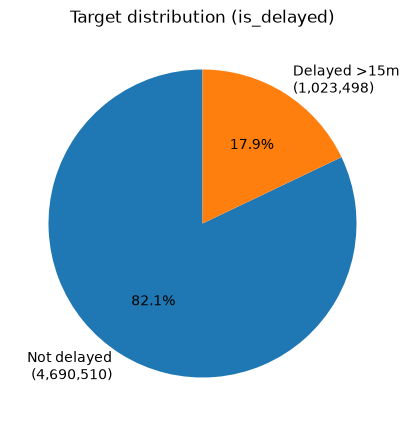

In [9]:
import matplotlib.pyplot as plt

valid_flights = (
    df_parsed
    .filter(F.col("ARRIVAL_DELAY").isNotNull())
    .withColumn("is_delayed", (F.col("ARRIVAL_DELAY") > 15).cast("int"))
)

counts = valid_flights.groupBy("is_delayed").count().orderBy("is_delayed").toPandas()
labels = [f"{'Delayed >15m' if r.is_delayed else 'Not delayed'}\n({r['count']:,})" for _, r in counts.iterrows()]

plt.figure(figsize=(5, 5))
plt.pie(counts["count"], labels=labels, autopct="%.1f%%", startangle=90)
plt.title("Target distribution (is_delayed)")
plt.show()

This shows a clear class imbalance where **82.1%** are not delayed (`4,690,510`) and **17.9%** are delayed (`1,023,498`).


### **3.4) Correlations with the target**
Next, we check linear correlations between numeric columns and `is_delayed` on flights with a non-null `ARRIVAL_DELAY`, to spot which numeric features move with delays and which columns happen after takeoff.

In [10]:
all_numeric_cols = [
    "YEAR", "MONTH", "DAY", "DAY_OF_WEEK", "FLIGHT_NUMBER",
    "SCHEDULED_DEPARTURE", "DEPARTURE_TIME", "DEPARTURE_DELAY",
    "TAXI_OUT", "WHEELS_OFF", "SCHEDULED_TIME", "ELAPSED_TIME",
    "AIR_TIME", "DISTANCE", "WHEELS_ON", "TAXI_IN",
    "SCHEDULED_ARRIVAL", "ARRIVAL_TIME", "ARRIVAL_DELAY",
    "DIVERTED", "CANCELLED", "AIR_SYSTEM_DELAY", "SECURITY_DELAY",
    "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"
]

correlations = valid_flights.select(
      [F.corr(F.col(c).cast("double"), F.col("is_delayed")).alias(c) for c in all_numeric_cols]
).first().asDict()

# drop any column where correlation couldn't be computed (all-null column, or constant column like YEAR)
correlations = {k: v for k, v in correlations.items() if v is not None}

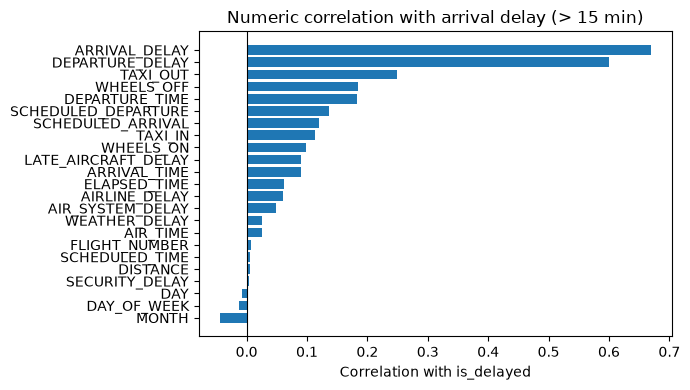

In [11]:
import matplotlib.pyplot as plt

corr_series = sorted(correlations.items(), key=lambda x: x[1])
labels = [item[0] for item in corr_series]
values = [item[1] for item in corr_series]

plt.figure(figsize=(7, 4))
plt.barh(labels, values)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with is_delayed")
plt.title("Numeric correlation with arrival delay (> 15 min)")
plt.tight_layout()
plt.show()

Only pre-departure columns are tested here. `SCHEDULED_DEPARTURE` (about `0.14`) has the strongest positive link: later flights are delayed more often (delays pile up during the day). `MONTH` is slightly negative (about `-0.04`), and the other columns sit close to zero. Linear correlations are weak overall, so we should expect a modest AUC.

### Staistical findings:
Three main facts will guide how we clean the data and build our model:
1. **Missing values aren't random:** `ARRIVAL_DELAY` is missing on cancelled/diverted flights, and delay-cause fields only show up on delayed flights—so we drop cancelled/diverted flights and keep only relevant columns.
2. **Unuseful columns and class imbalance:** `DEPARTURE_DELAY` and `TAXI_OUT` happen after/during takeoff, so they can't be used for pre-departure predictions. Also, most flights aren't delayed (~82% vs ~18%), so accuracy alone isn't enough later.
3. **Unique text values need cleanup:** Across the full dataset, `TAIL_NUMBER` has 4,897 unique values and the airport columns have 629 / 628 (including non-standard numeric codes), compared to 14 airlines and 4 cancellation reasons—so we'll clean odd codes and group rare values carefully.

## **4) Clean the data**
### **4.1) Missing values + incomplete flights**
Now we move to the full dataset (`df_parsed`) to build a clean table with no missing values. 
We'll also remove cancelled or diverted flights (since they don't have normal arrival delays) along with any rows missing key fields like `ARRIVAL_DELAY`, `SCHEDULED_TIME`, `DISTANCE`, or `SCHEDULED_DEPARTURE`, leaving only complete flights we can actually use.

In [12]:
cols = [
    "MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE",
    "ORIGIN_AIRPORT", "DESTINATION_AIRPORT",
    "SCHEDULED_DEPARTURE", "SCHEDULED_TIME", "DISTANCE",
    "ARRIVAL_DELAY", "CANCELLED", "DIVERTED"
]

df_clean = df_parsed.select(cols)
n_start = n_raw  # already counted in step 1
print(f"Start rows: {n_start:,}")

df_clean = (
    df_clean
    .filter((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0))
    .dropna(subset=[
        "MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE",
        "ORIGIN_AIRPORT", "DESTINATION_AIRPORT",
        "SCHEDULED_DEPARTURE", "SCHEDULED_TIME", "DISTANCE",
        "ARRIVAL_DELAY"
    ])
)

n_after_missing = df_clean.count()
print(f"After missing & cancelled/diverted drop: {n_after_missing:,} (dropped {n_start - n_after_missing:,})")

Start rows: 5,819,079


After missing & cancelled/diverted drop: 5,714,008 (dropped 105,071)


### **4.2) Removing duplicate rows**
Next, we drop exact duplicate rows with `dropDuplicates()` so repeated flights don't bias training, and check the row count before and after.

In [13]:
before_dedup = n_after_missing  # already counted above
# cache right after the expensive shuffle: every later step (filters, features, indexer, export) reads from memory
df_clean = df_clean.dropDuplicates().cache()
after_dedup = df_clean.count()

print(f"After dropDuplicates: {after_dedup:,} (dropped {before_dedup - after_dedup:,})")

After dropDuplicates: 5,714,005 (dropped 3)


### **4.3) Filtering impossible values and outliers**
Here we remove non-standard numeric airport codes, require positive scheduled times and distances, and keep `ARRIVAL_DELAY` within `[-120, 1500]` minutes to filter extreme outliers while logging the row count before and after.

In [14]:
# all checks in a single pass over the cached data
checks = df_clean.select(
    F.sum(F.col("ORIGIN_AIRPORT").rlike("^[0-9]+$").cast("int")).alias("num_origins"),
    F.sum(F.col("DESTINATION_AIRPORT").rlike("^[0-9]+$").cast("int")).alias("num_dests"),
    F.min("ARRIVAL_DELAY").alias("min_delay"),
    F.max("ARRIVAL_DELAY").alias("max_delay"),
    F.min("SCHEDULED_TIME").alias("min_sched_time"),
    F.min("DISTANCE").alias("min_dist")
).first()
print(f"Numeric airport rows -> origin: {checks.num_origins:,}, dest: {checks.num_dests:,}")
print(f"ARRIVAL_DELAY min/max: {checks.min_delay} / {checks.max_delay} | "
      f"min SCHEDULED_TIME: {checks.min_sched_time} | min DISTANCE: {checks.min_dist}")

# Step 2 inside 4.3: filter and log row count before and after
before_outliers = after_dedup  # already counted in 4.2

df_clean = (
    df_clean
    .filter(~F.col("ORIGIN_AIRPORT").rlike("^[0-9]+$") & ~F.col("DESTINATION_AIRPORT").rlike("^[0-9]+$"))
    .filter(
        (F.col("SCHEDULED_TIME") > 0) &
        (F.col("DISTANCE") > 0) &
        (F.col("ARRIVAL_DELAY").between(-120, 1500))
    )
)

after_outliers = df_clean.count()
print(f"After impossible/outlier filter: {after_outliers:,} (dropped {before_outliers - after_outliers:,})")

Numeric airport rows -> origin: 482,877, dest: 482,877
ARRIVAL_DELAY min/max: -87.0 / 1971.0 | min SCHEDULED_TIME: 18.0 | min DISTANCE: 31.0


After impossible/outlier filter: 5,231,110 (dropped 482,895)


Based on what we just checked, we see delays reaching up to `1,971` minutes while scheduled times (`18` min minimum) and distances (`31` mi minimum) are already positive. 
Filtering out numeric airport codes and extreme `ARRIVAL_DELAY` values outside `[-120, 1500]` minutes removed **482,895** rows, leaving **5,231,110** clean flights.

### **4.5) Feature engineering:**
#### **4.5.1) Departure hour**

`SCHEDULED_DEPARTURE` stores time as `HHMM` numbers. First we turn `2400` (midnight) into `0` so it never becomes hour `24`, then we divide by `100` to pull out the **hour of day** (`0` to `23`) as a cleaner feature for the model.

In [15]:
df_feat = df_clean.withColumn(
    "sched_dep_clean",
    F.when(F.col("SCHEDULED_DEPARTURE") == 2400, 0).otherwise(F.col("SCHEDULED_DEPARTURE").cast("int"))
)

df_feat = df_feat.withColumn(
    "dep_hour",
    (F.col("sched_dep_clean") / 100).cast("int")
)

# to check if dep_hour between 0 and 23
df_feat.select("SCHEDULED_DEPARTURE", "sched_dep_clean", "dep_hour").show(5)
df_feat.select(F.min("dep_hour").alias("min_hour"), F.max("dep_hour").alias("max_hour")).show()

+-------------------+---------------+--------+
|SCHEDULED_DEPARTURE|sched_dep_clean|dep_hour|
+-------------------+---------------+--------+
|              120.0|            120|       1|
|              127.0|            127|       1|
|              520.0|            520|       5|
|              530.0|            530|       5|
|              538.0|            538|       5|
+-------------------+---------------+--------+
only showing top 5 rows


+--------+--------+
|min_hour|max_hour|
+--------+--------+
|       0|      23|
+--------+--------+



#### **4.5.2) Create the target label**
We create `label` (`1` if `ARRIVAL_DELAY > 15` minutes, `0` otherwise) so the target column is ready for classification.

In [16]:
df_feat = df_feat.withColumn(
    "label",
    F.when(F.col("ARRIVAL_DELAY") > 15, 1.0).otherwise(0.0)
)

# no extra cache: df_feat is a cheap filter + new columns on top of the cached df_clean
df_feat.select("dep_hour", "ARRIVAL_DELAY", "label").show(5)

+--------+-------------+-----+
|dep_hour|ARRIVAL_DELAY|label|
+--------+-------------+-----+
|       1|          2.0|  0.0|
|       1|        -16.0|  0.0|
|       5|         54.0|  1.0|
|       5|        -18.0|  0.0|
|       5|        -16.0|  0.0|
+--------+-------------+-----+
only showing top 5 rows


#### **4.5.2) Encode text/categorical columns**
Spark ML models expect numbers rather than raw text. We first convert `AIRLINE`, `ORIGIN_AIRPORT`, and `DESTINATION_AIRPORT` into numeric indices using `StringIndexer`, then turn those indices into one-hot vectors using `OneHotEncoder`.

In [17]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder

cat_cols = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]
idx_cols = ["airline_idx", "origin_idx", "dest_idx"]
ohe_cols = ["airline_ohe", "origin_ohe", "dest_ohe"]

indexer = StringIndexer(
    inputCols=cat_cols,
    outputCols=idx_cols,
    handleInvalid="keep"
)
indexer_model = indexer.fit(df_feat)  # kept: its labels are exported for the Streamlit app
df_indexed = indexer_model.transform(df_feat)

encoder = OneHotEncoder(
    inputCols=idx_cols,
    outputCols=ohe_cols
)
df_encoded = encoder.fit(df_indexed).transform(df_indexed)

df_encoded.select("AIRLINE", "airline_idx", "airline_ohe", "label").show(5, truncate=False)

+-------+-----------+---------------+-----+
|AIRLINE|airline_idx|airline_ohe    |label|
+-------+-----------+---------------+-----+
|AA     |2.0        |(14,[2],[1.0]) |0.0  |
|AA     |2.0        |(14,[2],[1.0]) |0.0  |
|AA     |2.0        |(14,[2],[1.0]) |1.0  |
|F9     |11.0       |(14,[11],[1.0])|0.0  |
|OO     |3.0        |(14,[3],[1.0]) |0.0  |
+-------+-----------+---------------+-----+
only showing top 5 rows


Each categorical column now has a clean index (`*_idx`) and one-hot encoded vector (`*_ohe`) without manually writing messy mapping rules.

## **5) Model Training**
### **5.1) Sample, split & normalize (MLP, XGBoost and Random Forest)**

Collecting 5.2M rows × ~660 one-hot columns into Python does not fit in memory (this cell used to run for 10+ minutes and kill the kernel). So we:
1. take a random sample (`SAMPLE_FRACTION`, 15% by default ≈ 780k flights),
2. bring only 10 small columns to the driver with Arrow (6 numbers, 3 category indices, the label),
3. rebuild the one-hot vectors in NumPy, directly into one preallocated float32 matrix,
4. shuffle and split 70% train / 10% validation (threshold tuning) / 20% test.

Only the numeric columns are standardized (mean/std from the train set only); one-hot columns stay 0/1.

In [18]:
import os
import numpy as np

SAMPLE_FRACTION = float(os.environ.get("SAMPLE_FRACTION", "0.15"))
num_cols = ["MONTH", "DAY", "DAY_OF_WEEK", "SCHEDULED_TIME", "DISTANCE", "dep_hour"]

pdf = (df_indexed
       .sample(fraction=SAMPLE_FRACTION, seed=42)
       .select(*num_cols, *idx_cols, "label")
       .toPandas())
print(f"Rows used for the MLP, XGBoost and the Random Forest: {len(pdf):,}")

# +1: handleInvalid="keep" adds one extra index for unseen values
n_cats = [len(labels) + 1 for labels in indexer_model.labelsArray]

rng = np.random.default_rng(42)
perm = rng.permutation(len(pdf))
n_test, n_val = int(0.2 * len(perm)), int(0.1 * len(perm))
test_i, val_i, train_i = perm[:n_test], perm[n_test:n_test + n_val], perm[n_test + n_val:]

mean = pdf.iloc[train_i][num_cols].mean().to_numpy(np.float32)
std = pdf.iloc[train_i][num_cols].std().replace(0, 1).to_numpy(np.float32)

offsets = np.cumsum([len(num_cols)] + n_cats[:-1])
n_features = len(num_cols) + sum(n_cats)

def to_features(frame):
    # one preallocated matrix: no per-column one-hot copies, no hstack copy
    X = np.zeros((len(frame), n_features), dtype=np.float32)
    X[:, :len(num_cols)] = (frame[num_cols].to_numpy(np.float32) - mean) / std
    rows = np.arange(len(frame))
    for c, off in zip(idx_cols, offsets):
        X[rows, off + frame[c].to_numpy(int)] = 1.0
    return X

X_train, X_val, X_test = (to_features(pdf.iloc[i]) for i in (train_i, val_i, test_i))
labels = pdf["label"].to_numpy(np.float32)
y_train, y_val, y_test = labels[train_i], labels[val_i], labels[test_i]

print("Train / val / test:", X_train.shape, X_val.shape, X_test.shape)
print(f"Feature matrices: {(X_train.nbytes + X_val.nbytes + X_test.nbytes) / 1e9:.2f} GB")
print(f"Delayed share in train: {y_train.mean():.1%}")

/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Rows used for the MLP, XGBoost and the Random Forest: 785,169


Train / val / test: (549620, 667) (78516, 667) (157033, 667)
Feature matrices: 2.09 GB
Delayed share in train: 18.4%


### **5.2) Evaluation helpers (metrics, confusion matrix, threshold)**

`evaluate` computes (NumPy only) Accuracy, Precision, Recall, F1, AUC and the confusion matrix at a given threshold, and returns a row for `model_scores.csv`.

With only ~18% delayed flights, a 0.5 threshold predicts almost nothing as delayed. `best_threshold` picks the threshold that maximizes F1 on the **validation** set (never on the test set).

In [19]:
def auc_score(y_true, y_prob):
    # AUC = probability that a delayed flight scores above an on-time one (rank formula, ties averaged)
    y_true = np.asarray(y_true).ravel() == 1
    ranks = pd.Series(np.asarray(y_prob).ravel()).rank().to_numpy()
    n_pos, n_neg = y_true.sum(), (~y_true).sum()
    return float((ranks[y_true].sum() - n_pos * (n_pos + 1) / 2) / max(n_pos * n_neg, 1))


def evaluate(y_true, y_prob, name="Model", threshold=0.5):
    y_true = np.asarray(y_true).ravel() == 1
    y_prob = np.asarray(y_prob).ravel()
    pred = y_prob >= threshold
    tp = int(np.sum(pred & y_true))
    fp = int(np.sum(pred & ~y_true))
    fn = int(np.sum(~pred & y_true))
    tn = int(np.sum(~pred & ~y_true))

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * tp / max(2 * tp + fp + fn, 1)
    auc = auc_score(y_true, y_prob)

    print(f"=== {name} (threshold {threshold:.2f}) ===")
    print(f"Accuracy : {accuracy:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f} | AUC: {auc:.4f}")
    print("Confusion Matrix [[TN, FP], [FN, TP]]:")
    print(np.array([[tn, fp], [fn, tp]]))
    return {"model": name, "accuracy": accuracy, "f1": f1, "auc": auc, "threshold": float(threshold)}


def best_threshold(y_true, y_prob):
    y_true = np.asarray(y_true).ravel() == 1
    y_prob = np.asarray(y_prob).ravel()
    best_t, best_f1 = 0.5, -1.0
    for t in np.arange(0.05, 0.95, 0.01):
        pred = y_prob >= t
        tp = np.sum(pred & y_true)
        fp = np.sum(pred & ~y_true)
        fn = np.sum(~pred & y_true)
        f1 = 2 * tp / max(2 * tp + fp + fn, 1)
        if f1 > best_f1:
            best_t, best_f1 = float(t), f1
    return best_t


# self-checks
assert 0.2 < best_threshold([0, 0, 1, 1], [0.1, 0.2, 0.8, 0.9]) <= 0.8
assert auc_score([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]) == 0.75

results = []
models = {}


### **5.3) Logistic Regression (Spark ML Pipeline)**

This model is trained entirely with `pyspark.ml`, as the course asks: its own 5% sample, split with `randomSplit([0.8, 0.2], seed=42)`.
The `Pipeline` chains `StringIndexer` → `OneHotEncoder` → `VectorAssembler` → `LogisticRegression` (with `standardization=True`, so no separate scaler).

A majority-class baseline (always "not delayed") shows what the model has to beat: high accuracy, but an AUC of 0.5 and no delay detected.

Two differences with XGBoost and the Random Forest, to keep in mind when comparing:

- its test set is not the same rows (5% Spark sample, not the 15% pandas sample);
- it keeps Spark's default 0.5 threshold, while the other models use a threshold tuned on validation (so compare it on AUC).


In [20]:
from pyspark import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import time

spark_ml_fraction = 0.05
spark_ml_seed = 42
spark_ml_cat_cols = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]
spark_ml_num_cols = ["MONTH", "DAY", "DAY_OF_WEEK", "SCHEDULED_TIME", "DISTANCE", "dep_hour"]
assert 0 < spark_ml_fraction <= 1
spark_ml_population = df_feat.select(*(spark_ml_cat_cols + spark_ml_num_cols + ["label"]))
spark_ml_sample = spark_ml_population.sample(False, spark_ml_fraction, spark_ml_seed).persist(StorageLevel.MEMORY_ONLY)
spark_ml_sample_count = spark_ml_sample.count()
spark_ml_train, spark_ml_test = spark_ml_sample.randomSplit([0.8, 0.2], seed=spark_ml_seed)
spark_ml_train = spark_ml_train.persist(StorageLevel.MEMORY_ONLY)
spark_ml_test = spark_ml_test.persist(StorageLevel.MEMORY_ONLY)
spark_ml_train_count = spark_ml_train.count()
spark_ml_test_count = spark_ml_test.count()
assert spark_ml_train_count + spark_ml_test_count == spark_ml_sample_count
assert spark_ml_train_count > 0 and spark_ml_test_count > 0
print(f"Population nettoyée : {after_outliers:,} | fraction ML : {spark_ml_fraction:.0%}")
print(f"Échantillon ML : {spark_ml_sample_count:,} | train : {spark_ml_train_count:,} | test : {spark_ml_test_count:,}")
print("Classes dans le train :")
spark_ml_train.groupBy("label").count().orderBy("label").show()
print("Classes dans le test :")
spark_ml_test.groupBy("label").count().orderBy("label").show()


Population nettoyée : 5,231,110 | fraction ML : 5%
Échantillon ML : 261,005 | train : 209,228 | test : 51,777
Classes dans le train :
+-----+------+
|label| count|
+-----+------+
|  0.0|170466|
|  1.0| 38762|
+-----+------+

Classes dans le test :


+-----+-----+
|label|count|
+-----+-----+
|  0.0|42114|
|  1.0| 9663|
+-----+-----+



In [21]:
def spark_ml_pipeline():
    indexer = StringIndexer(
        inputCols=spark_ml_cat_cols,
        outputCols=["spark_ml_airline_idx", "spark_ml_origin_idx", "spark_ml_dest_idx"],
        handleInvalid="keep"
    )
    encoder = OneHotEncoder(
        inputCols=indexer.getOutputCols(),
        outputCols=["spark_ml_airline_vec", "spark_ml_origin_vec", "spark_ml_dest_vec"]
    )
    assembler = VectorAssembler(
        inputCols=spark_ml_num_cols + encoder.getOutputCols(),
        outputCol="spark_ml_features"
    )
    classifier = LogisticRegression(
        featuresCol="spark_ml_features", labelCol="label",
        maxIter=30, regParam=0.05, standardization=True
    )
    return Pipeline(stages=[indexer, encoder, assembler, classifier])

spark_ml_model_name = "LogisticRegression"
def spark_ml_metrics(frame, name, duration=0.0):
    accuracy = MulticlassClassificationEvaluator(metricName="accuracy").evaluate(frame)
    weighted_f1 = MulticlassClassificationEvaluator(metricName="f1").evaluate(frame)
    auc = BinaryClassificationEvaluator(rawPredictionCol="spark_ml_score", metricName="areaUnderROC").evaluate(frame)
    counts = {(int(r["label"]), int(r["prediction"])): r["count"]
              for r in frame.groupBy("label", "prediction").count().collect()}
    tn, fp = counts.get((0, 0), 0), counts.get((0, 1), 0)
    fn, tp = counts.get((1, 0), 0), counts.get((1, 1), 0)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    positive_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    print(f"{name} | accuracy={accuracy:.4f} | F1 pondéré={weighted_f1:.4f} | AUC={auc:.4f}")
    print(f"Retard : précision={precision:.4f} | rappel={recall:.4f} | F1={positive_f1:.4f}")
    print(f"Matrice [[TN, FP], [FN, TP]] : [[{tn}, {fp}], [{fn}, {tp}]]")
    return dict(model=name, accuracy=accuracy, f1=weighted_f1, auc=auc,
                precision_delay=precision, recall_delay=recall, f1_delay=positive_f1,
                tn=tn, fp=fp, fn=fn, tp=tp, train_seconds=duration,
                sample_fraction=spark_ml_fraction, train_rows=spark_ml_train_count,
                test_rows=spark_ml_test_count)

spark_ml_majority = spark_ml_train.groupBy("label").count().orderBy(F.desc("count"), F.asc("label")).first()["label"]
spark_ml_baseline_frame = spark_ml_test.select("label").withColumn("prediction", F.lit(float(spark_ml_majority))).withColumn("spark_ml_score", F.lit(float(spark_ml_majority)))
spark_ml_baseline = spark_ml_metrics(spark_ml_baseline_frame, "BaselineMajoritaire")


BaselineMajoritaire | accuracy=0.8134 | F1 pondéré=0.7297 | AUC=0.5000
Retard : précision=0.0000 | rappel=0.0000 | F1=0.0000
Matrice [[TN, FP], [FN, TP]] : [[42114, 0], [9663, 0]]


In [22]:
from pyspark.ml.functions import vector_to_array

spark_ml_start = time.perf_counter()
spark_ml_model = spark_ml_pipeline().fit(spark_ml_train)
spark_ml_duration = time.perf_counter() - spark_ml_start
spark_ml_predictions = spark_ml_model.transform(spark_ml_test)
spark_ml_evaluation = spark_ml_predictions.select(
    "label", "prediction", vector_to_array("probability")[1].alias("spark_ml_score")
).persist(StorageLevel.MEMORY_ONLY)
try:
    assert spark_ml_evaluation.count() == spark_ml_test_count
    spark_ml_result = spark_ml_metrics(spark_ml_evaluation, spark_ml_model_name, spark_ml_duration)
finally:
    spark_ml_evaluation.unpersist()
print("Durée d'entraînement (secondes) :", round(spark_ml_duration, 1))
print("Dimensions des features :", spark_ml_model.stages[-1].numFeatures)


LogisticRegression | accuracy=0.8133 | F1 pondéré=0.7296 | AUC=0.6349
Retard : précision=0.0000 | rappel=0.0000 | F1=0.0000
Matrice [[TN, FP], [FN, TP]] : [[42111, 3], [9663, 0]]
Durée d'entraînement (secondes) : 3.8
Dimensions des features : 663


In [23]:
spark_ml_scores = pd.DataFrame([spark_ml_result])
spark_ml_comparison = pd.DataFrame([spark_ml_baseline, spark_ml_result])
display(spark_ml_comparison[["model", "accuracy", "f1", "auc", "recall_delay"]].round(4))
print(f"Un seul modèle Spark entraîné ; évaluation sur {spark_ml_test_count:,} vols de test.")


,model,accuracy,f1,auc,recall_delay
0,BaselineMajoritaire,0.8134,0.7297,0.5000,0.0
1,LogisticRegression,0.8133,0.7296,0.6349,0.0


Un seul modèle Spark entraîné ; évaluation sur 51,777 vols de test.


In [24]:
# add the Spark model to the comparison with XGBoost and the RF (model_scores.csv, threshold_curves.csv)
# f1 = F1 of the delayed class, like the other models (not the weighted F1); Spark's default threshold is 0.5
results.append({"model": "Logistic Regression (Spark)", "accuracy": spark_ml_result["accuracy"],
                "f1": spark_ml_result["f1_delay"], "auc": spark_ml_result["auc"], "threshold": 0.5})
spark_ml_scored = spark_ml_predictions.select("label", vector_to_array("probability")[1].alias("p")).toPandas()
spark_lr_y_test, spark_lr_probs = spark_ml_scored["label"].to_numpy(), spark_ml_scored["p"].to_numpy()


/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


### **5.4) Multi-Layer Neural Network (TensorFlow Sequential)**

Adds Dense (ReLU) hidden layers and Dropout to learn non-linear relationships across flight, time, and route features.

In [25]:
import tensorflow as tf

# stop when val_loss stops improving and keep the best epoch (the MLP overfits after a few epochs)
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, min_delta=1e-4, restore_best_weights=True)

tf.random.set_seed(42)

mlp_tf = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

mlp_tf.compile(optimizer="adam", loss="binary_crossentropy")
mlp_tf.fit(
    X_train, y_train,
    epochs=30,
    batch_size=1024,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=2
)

mlp_t = best_threshold(y_val, mlp_tf.predict(X_val, batch_size=4096, verbose=0))
mlp_probs = mlp_tf.predict(X_test, batch_size=4096, verbose=0)
results.append(evaluate(y_test, mlp_probs, "Neural Network MLP (TF)", mlp_t))
models["Neural Network MLP (TF)"] = mlp_tf

Epoch 1/30


537/537 - 2s - 4ms/step - loss: 0.4639 - val_loss: 0.4504


Epoch 2/30


537/537 - 1s - 3ms/step - loss: 0.4549 - val_loss: 0.4485


Epoch 3/30


537/537 - 1s - 3ms/step - loss: 0.4519 - val_loss: 0.4470


... (19 outputs left out)

537/537 - 1s - 3ms/step - loss: 0.4350 - val_loss: 0.4405


Epoch 14/30


537/537 - 2s - 3ms/step - loss: 0.4340 - val_loss: 0.4405


=== Neural Network MLP (TF) (threshold 0.18) ===
Accuracy : 0.6360 | Precision: 0.2795 | Recall: 0.6173 | F1: 0.3848 | AUC: 0.6789
Confusion Matrix [[TN, FP], [FN, TP]]:
[[82001 46073]
 [11083 17876]]


### **5.5) XGBoost (gradient-boosted trees)**

Trees split on thresholds and combine features on their own (airline × airport × hour), which linear models cannot do. We train on the same one-hot matrices as the MLP (built in 5.1) (scaling does not matter for trees) with the `hist` method, and stop adding trees when the validation log-loss stops improving.

In [26]:
import xgboost as xgb

dtrain = xgb.QuantileDMatrix(X_train, label=y_train)
dval = xgb.QuantileDMatrix(X_val, label=y_val, ref=dtrain)
params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "eta": 0.1,
    "max_depth": 8,
    "tree_method": "hist",
    "nthread": -1,
    "seed": 42,
}
xgb_model = xgb.train(params, dtrain, num_boost_round=1000, evals=[(dval, "val")],
                      early_stopping_rounds=20, verbose_eval=50)
print("Best iteration:", xgb_model.best_iteration)
# keep only the trees up to the best iteration, so the saved model predicts like the evaluated one
xgb_model = xgb_model[: xgb_model.best_iteration + 1]

xgb_t = best_threshold(y_val, xgb_model.predict(xgb.DMatrix(X_val)))
xgb_probs = xgb_model.predict(xgb.DMatrix(X_test))
results.append(evaluate(y_test, xgb_probs, "XGBoost", xgb_t))
models["XGBoost"] = xgb_model

[0]	val-logloss:0.46941


[50]	val-logloss:0.43446


[100]	val-logloss:0.42885


[150]	val-logloss:0.42617


[200]	val-logloss:0.42497


[250]	val-logloss:0.42400


... (2 outputs left out)

[400]	val-logloss:0.42130


[413]	val-logloss:0.42132


Best iteration: 393


=== XGBoost (threshold 0.23) ===
Accuracy : 0.7404 | Precision: 0.3610 | Recall: 0.5294 | F1: 0.4293 | AUC: 0.7239
Confusion Matrix [[TN, FP], [FN, TP]]:
[[100931  27143]
 [ 13627  15332]]


### **5.6) Random Forest (Spark MLlib)**

Many decision trees, each trained on a random half of the flights and a random subset of features at each split; the forest averages their votes. We train it with Spark on the **same train/validation/test rows** as the other models, so the scores are comparable.

Trees need neither scaling nor one-hot: the model takes the 6 raw numeric columns and the 3 category indices (10 values instead of 667).

In [27]:
from pyspark.ml.classification import RandomForestClassifier, RandomForestClassificationModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.functions import vector_to_array

rf_cols = num_cols + idx_cols
rf_assembler = VectorAssembler(inputCols=rf_cols, outputCol="features")

def to_spark(rows):
    return rf_assembler.transform(spark.createDataFrame(pdf.iloc[rows][rf_cols + ["label"]]))

rf = RandomForestClassifier(
    numTrees=100,
    maxDepth=10,  # 12 ran out of Java heap: each extra level doubles the per-node statistics
    maxBins=64,
    subsamplingRate=0.5,  # each tree sees half of the train set: faster, more diverse trees
    featureSubsetStrategy="sqrt",
    seed=42,
)
rf_model = rf.fit(to_spark(train_i))

def rf_predict(rows):
    # keep the label next to the probability so the order can never get mixed up
    out = (rf_model.transform(to_spark(rows))
           .select("label", vector_to_array("probability")[1].alias("p"))
           .toPandas())
    return out["label"].to_numpy(np.float32), out["p"].to_numpy(np.float32)

rf_t = best_threshold(*rf_predict(val_i))
rf_y_test, rf_probs = rf_predict(test_i)
results.append(evaluate(rf_y_test, rf_probs, "Random Forest (Spark)", rf_t))
models["Random Forest (Spark)"] = rf_model

/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:676: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:953: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/20 13:14:02 WARN TaskSetManager: Stage 254 contains a task of very large size (2223 KiB). The maximum recommended task size is 1000 KiB.


26/11/20 13:14:05 WARN TaskSetManager: Stage 257 contains a task of very large size (11884 KiB). The maximum recommended task size is 1000 KiB.
26/11/20 13:14:05 WARN TaskSetManager: Stage 258 contains a task of very large size (11884 KiB). The maximum recommended task size is 1000 KiB.


26/11/20 13:14:06 WARN TaskSetManager: Stage 259 contains a task of very large size (11884 KiB). The maximum recommended task size is 1000 KiB.


26/11/20 13:14:06 WARN TaskSetManager: Stage 261 contains a task of very large size (11884 KiB). The maximum recommended task size is 1000 KiB.


26/11/20 13:14:09 WARN TaskSetManager: Stage 263 contains a task of very large size (11884 KiB). The maximum recommended task size is 1000 KiB.


... (10 outputs left out)

26/11/20 13:15:17 WARN DAGScheduler: Broadcasting large task binary with size 3.6 MiB


/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:676: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:953: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


=== Random Forest (Spark) (threshold 0.20) ===
Accuracy : 0.6291 | Precision: 0.2693 | Recall: 0.5901 | F1: 0.3698 | AUC: 0.6651
Confusion Matrix [[TN, FP], [FN, TP]]:
[[81702 46372]
 [11870 17089]]


## **6) Save the results for Streamlit**

Streamlit does not need HDFS or model training: it reads small files from `app/`.

- `app/data/stats_airline.csv`: `AIRLINE, flights, avg_arr_delay, delay_rate_pct` (full cleaned dataset)
- `app/data/stats_hour.csv`: `dep_hour, flights, avg_arr_delay` (full cleaned dataset)
- `app/data/routes.csv`: `ORIGIN_AIRPORT, DESTINATION_AIRPORT, AIRLINE, flights, sched_time, distance` (medians per route and airline: the predict page uses it to list only real routes/airlines and to fill duration and distance)
- `app/data/stats_detail.csv`: `AIRLINE, MONTH, dep_hour, flights, delayed, sum_arr_delay` (one row per airline × month × hour: the explore page filters and re-aggregates it)
- `app/data/threshold_curves.csv`: `model, threshold, precision, recall, f1` (test set, per model)
- `app/data/correlation.csv`: Pearson correlation matrix of the numeric features and `label` (15% sample used for training)
- `app/data/model_scores.csv`: `model, accuracy, f1, auc, threshold` (test set)
- `app/models/neural_network_mlp_tf.keras` / `xgboost.json` / `random_forest_spark/`: the MLP, XGBoost and the Random Forest (the predict page shows them side by side). The Spark logistic regression pipeline is scored but not exported: the app cannot build its Spark input.
- `app/models/preprocessing.json`: everything needed to rebuild the input vector (column order, mean/std, category labels) and, per model, its file, threshold and test AUC

In [28]:
import json
import re
import pandas as pd

DATA_DIR = "../app/data"
MODEL_DIR = "../app/models"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

stats_airline = (df_feat.groupBy("AIRLINE")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("ARRIVAL_DELAY"), 2).alias("avg_arr_delay"),
        F.round(F.avg("label") * 100, 1).alias("delay_rate_pct")
    )
    .orderBy(F.desc("avg_arr_delay")))
stats_airline.toPandas().to_csv(f"{DATA_DIR}/stats_airline.csv", index=False)

stats_hour = (df_feat.groupBy("dep_hour")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("ARRIVAL_DELAY"), 2).alias("avg_arr_delay")
    )
    .orderBy("dep_hour"))
stats_hour.toPandas().to_csv(f"{DATA_DIR}/stats_hour.csv", index=False)

routes = (df_feat.groupBy("ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "AIRLINE")
    .agg(
        F.count("*").alias("flights"),
        F.percentile_approx("SCHEDULED_TIME", 0.5).alias("sched_time"),
        F.percentile_approx("DISTANCE", 0.5).alias("distance")
    )
    .orderBy("ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "AIRLINE"))
routes.toPandas().to_csv(f"{DATA_DIR}/routes.csv", index=False)

stats_detail = (df_feat
    .groupBy("AIRLINE", F.col("MONTH").cast("int").alias("MONTH"), "dep_hour")
    .agg(
        F.count("*").alias("flights"),
        F.sum("label").cast("int").alias("delayed"),
        F.round(F.sum("ARRIVAL_DELAY"), 1).alias("sum_arr_delay")
    )
    .orderBy("AIRLINE", "MONTH", "dep_hour"))
stats_detail.toPandas().to_csv(f"{DATA_DIR}/stats_detail.csv", index=False)

# precision / recall / F1 for every threshold, on the test set
test_probs = {
    "Logistic Regression (Spark)": (spark_lr_y_test, spark_lr_probs),
    "Neural Network MLP (TF)": (y_test, mlp_probs),
    "XGBoost": (y_test, xgb_probs),
    "Random Forest (Spark)": (rf_y_test, rf_probs),
}
curve_rows = []
for name, (y_true, y_prob) in test_probs.items():
    y_true = np.asarray(y_true).ravel() == 1
    y_prob = np.asarray(y_prob).ravel()
    for t in np.round(np.arange(0.02, 0.81, 0.01), 2):
        pred = y_prob >= t
        tp = int(np.sum(pred & y_true))
        fp = int(np.sum(pred & ~y_true))
        fn = int(np.sum(~pred & y_true))
        curve_rows.append({"model": name, "threshold": t,
                           "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                           "f1": 2 * tp / max(2 * tp + fp + fn, 1)})
pd.DataFrame(curve_rows).to_csv(f"{DATA_DIR}/threshold_curves.csv", index=False)

# correlation matrix of the numeric features and the target (same 15% sample as the models)
pdf[num_cols + ["label"]].corr().round(3).to_csv(f"{DATA_DIR}/correlation.csv")

scores = pd.DataFrame(results, columns=["model", "accuracy", "f1", "auc", "threshold"])
scores.to_csv(f"{DATA_DIR}/model_scores.csv", index=False)

saved_models = []
for row in scores.sort_values("auc", ascending=False).itertuples():
    if row.model not in models:
        continue  # Spark logistic regression: scored only, the app cannot rebuild its input
    slug = re.sub(r"[^a-z0-9]+", "_", row.model.lower()).strip("_")
    model = models[row.model]
    if isinstance(model, RandomForestClassificationModel):
        file = slug  # a folder ("random_forest_spark"): Spark saves models as directories
        model.write().overwrite().save("file://" + os.path.abspath(f"{MODEL_DIR}/{file}"))
    elif isinstance(model, xgb.Booster):
        file = f"{slug}.json"
        model.save_model(f"{MODEL_DIR}/{file}")
    else:
        file = f"{slug}.keras"
        model.save(f"{MODEL_DIR}/{file}")
    # "raw": 6 numbers + 3 category indices (Spark trees); "onehot": standardized numbers + one-hot (Keras, XGBoost)
    inputs = "raw" if isinstance(model, RandomForestClassificationModel) else "onehot"
    saved_models.append({"name": row.model, "file": file, "inputs": inputs,
                         "threshold": float(row.threshold), "auc": float(row.auc)})

preprocessing = {
    "models": saved_models,  # best AUC first
    "num_cols": num_cols,
    "mean": mean.tolist(),
    "std": std.tolist(),
    # one-hot order = labels order; an unknown value goes to the extra last slot
    "cat_cols": cat_cols,
    "cat_labels": [list(l) for l in indexer_model.labelsArray],
}
with open(f"{MODEL_DIR}/preprocessing.json", "w") as f:
    json.dump(preprocessing, f, indent=2)

print(scores)
print("Best model:", saved_models[0]["name"])
print("Data files:", os.listdir(DATA_DIR))
print("Model files:", os.listdir(MODEL_DIR))

/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/Volumes/Addons/Cours/ESGI/03_Annee/DelayFlightPrediction/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/20 13:16:14 WARN TaskSetManager: Stage 335 contains a task of very large size (1982 KiB). The maximum recommended task size is 1000 KiB.


                         model  accuracy        f1       auc  threshold
0  Logistic Regression (Spark)  0.813315  0.000000  0.634875       0.50
1      Neural Network MLP (TF)  0.636026  0.384811  0.678851       0.18
2                      XGBoost  0.740373  0.429263  0.723933       0.23
3        Random Forest (Spark)  0.629110  0.369812  0.665071       0.20
Best model: XGBoost
Data files: ['model_scores.csv', 'stats_airline.csv', 'stats_hour.csv', 'correlation.csv', 'routes.csv', 'threshold_curves.csv', 'stats_detail.csv']
Model files: ['neural_network_mlp_tf.keras', 'xgboost.json', 'preprocessing.json', 'random_forest_spark']
